# GSE193531 — Step 6: Pseudobulk Construction and Healthy vs. MM Differential Expression

Produces this cohort's primary differential expression result: Healthy
donor plasma cells vs. malignant (MM) plasma cells, at the patient level.

## Why pseudobulk, and why patient-level
Treating individual cells as independent replicates (cell-level DE) is
pseudoreplication: cells from the same patient are not independent
observations, and cell-level DE tests are well documented to produce badly
miscalibrated false-positive rates for exactly this reason (Squair et al.
2021, *Nat Commun*). Pseudobulk avoids this: raw UMI counts are summed
across cells **within each patient**, and the actual statistical test is
run across patients (the real biological replicates), using a
negative-binomial model designed for count data.

## Method decisions
1. **Cell selection is `malignancy_status`-filtered, not stage-only.** An MM
   sample can contain both malignant and residual normal plasma cells. The
   `Healthy` group is each Healthy patient's cells with
   `malignancy_status == "Normal"`; the `MM` group is each MM patient's
   cells with `malignancy_status == "Neoplastic"`.
2. **DESeq2 (R, via `rpy2`)** is used for the actual test — pseudobulk
   scRNA-seq DE is exactly the case DESeq2's negative-binomial model was
   built for.
3. Only `Healthy` and `MM` participate (`MGUS`/`SMM` are out of scope for
   this primary comparison).

## Requirements
This notebook needs R with Bioconductor's `DESeq2` package installed, and
the `rpy2` Python package to call it (see the repository README for setup).

**Input:** `data/processed/GSE193531/GSE193531_plasma_cells_classified.h5ad` (from notebook 05)

**Output:**
- `results/GSE193531/pseudobulk_deg/GSE193531_healthy_vs_mm_deseq2_results.csv`
- `results/GSE193531/pseudobulk_deg/GSE193531_pseudobulk_counts.csv`, `..._pseudobulk_sample_metadata.csv`
- volcano plot

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

import matplotlib.pyplot as plt

sc.settings.verbosity = 1

#### Directory layout and required files

In [2]:
PROJECT = Path("../")
COHORT = "GSE193531"

PROCESSED_DIR = PROJECT / "data" / "processed" / COHORT
RESULTS_DIR = PROJECT / "results" / COHORT

(RESULTS_DIR / "pseudobulk_deg").mkdir(parents=True, exist_ok=True)

INPUT_H5AD = PROCESSED_DIR / f"{COHORT}_plasma_cells_classified.h5ad"
if not INPUT_H5AD.exists():
    raise FileNotFoundError(INPUT_H5AD)

## Load Classified Plasma-Cell Object

In [3]:
adata = sc.read_h5ad(INPUT_H5AD)
print(adata)

for col in ["malignancy_status", "clinical_stage_standard", "patient_id"]:
    if col not in adata.obs.columns:
        raise KeyError(f"Expected column '{col}' not found in adata.obs.")

if "counts" not in adata.layers:
    raise KeyError("adata.layers['counts'] not found -- pseudobulk requires raw UMI counts.")

counts_sample = adata.layers["counts"][:500]
counts_sample = counts_sample.toarray() if hasattr(counts_sample, "toarray") else np.asarray(counts_sample)
if not np.allclose(counts_sample, np.round(counts_sample)):
    raise ValueError("adata.layers['counts'] does not look like raw integer counts.")

print(f"\nConfirmed: {adata.n_obs:,} cells, raw counts layer intact, required metadata present.")

AnnData object with n_obs × n_vars = 17500 × 22273
    obs: 'sample_id', 'patient_id', 'clinical_stage_standard', 'n_genes', 'doublet_score', 'predicted_doublet', 'n_counts', 'pct_mito', 'pct_ribo', 'pct_hb', 'pct_ig', 'complexity', 'leiden', 'cell_type_candidate', 'Plasma_cell_score', 'B_cell_score', 'CD4_T_score', 'CD8_T_score', 'NK_cell_score', 'Myeloid_score', 'pDC_score', 'Erythroid_score', 'cell_type', 'marker_positive', 'cluster_call', 'plasma_cell_confirmed', 'normal_or_neoplastic_raw', 'normal_or_neoplastic', 'kappa_counts', 'lambda_counts', 'light_chain_call', 'malignancy_status'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cell_type_candidate_colors', 'cell_type_colors', 'clinical_stage_standard_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'sample_id_colors', 'scrublet', 'umap'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

Confir

## Define Comparison Groups

`Healthy` group: cells with `clinical_stage_standard == "Healthy"` AND
`malignancy_status == "Normal"`. `MM` group: cells with
`clinical_stage_standard == "MM"` AND `malignancy_status == "Neoplastic"`.
`MGUS`/`SMM` cells are not part of this comparison.

In [4]:
adata.obs["pseudobulk_group"] = np.select(
    [
        (adata.obs["clinical_stage_standard"] == "Healthy") & (adata.obs["malignancy_status"] == "Normal"),
        (adata.obs["clinical_stage_standard"] == "MM") & (adata.obs["malignancy_status"] == "Neoplastic"),
    ],
    ["Healthy", "MM"],
    default="NA",
)

group_mask = adata.obs["pseudobulk_group"] != "NA"
print("Cells assigned to a pseudobulk group:")
print(adata.obs["pseudobulk_group"].value_counts())

patient_cell_counts = (
    adata.obs.loc[group_mask]
    .groupby(["patient_id", "pseudobulk_group"], observed=True)
    .size().rename("n_cells").reset_index()
    .sort_values(["pseudobulk_group", "n_cells"])
)
print("\nCells per patient, within its assigned group:")
display(patient_cell_counts)

Cells assigned to a pseudobulk group:
pseudobulk_group
Healthy    7000
NA         6220
MM         4280
Name: count, dtype: int64

Cells per patient, within its assigned group:


,patient_id,pseudobulk_group,n_cells
14,NBM-8,Healthy,41
10,NBM-3,Healthy,46
11,NBM-4,Healthy,134
12,NBM-6,Healthy,630
8,NBM-1,Healthy,655
9,NBM-2,Healthy,759
16,NBM-11,Healthy,764
13,NBM-7,Healthy,1480
15,NBM-10,Healthy,2491
1,MM-2,MM,1


## Minimum Cells per Pseudobulk Sample

The distribution of `n_cells` above is inspected directly rather than fit
to a derived statistic. `MIN_CELLS_PER_PSEUDOBULK = 10` is used as an
explicit, documented floor: low enough to avoid discarding patients
unnecessarily, and consistent with common practice for pseudobulk
minimum-cell floors in the scRNA-seq literature — a pragmatic choice, not a
value derived from this cohort's data.

Per-patient cell-count distribution (n=17 patients): min=1, median=630, max=2698
  floor =   5: would exclude 3 / 17 patients
  floor =  10: would exclude 3 / 17 patients
  floor =  15: would exclude 3 / 17 patients
  floor =  20: would exclude 3 / 17 patients


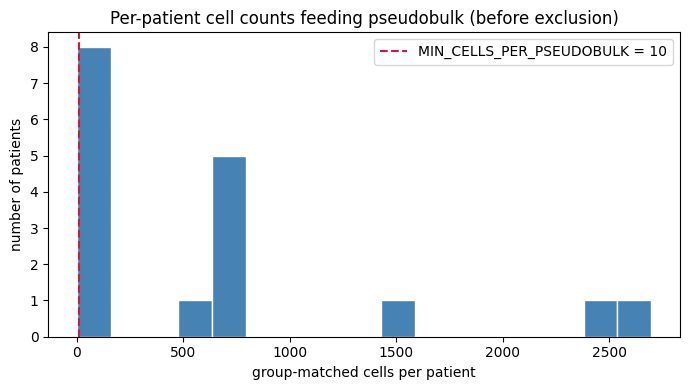

In [5]:
MIN_CELLS_PER_PSEUDOBULK = 10  # explicit, documented floor -- see markdown above; not derived from this cohort's data

n_cells_dist = patient_cell_counts["n_cells"]
print(f"Per-patient cell-count distribution (n={len(n_cells_dist)} patients): "
      f"min={n_cells_dist.min()}, median={n_cells_dist.median():.0f}, max={n_cells_dist.max()}")
for candidate in sorted({5, 10, 15, 20, MIN_CELLS_PER_PSEUDOBULK}):
    n_excluded = int((n_cells_dist < candidate).sum())
    print(f"  floor = {candidate:>3}: would exclude {n_excluded} / {len(n_cells_dist)} patients")

plt.figure(figsize=(7, 4))
plt.hist(n_cells_dist, bins=min(20, max(5, n_cells_dist.nunique())), color="steelblue", edgecolor="white")
plt.axvline(MIN_CELLS_PER_PSEUDOBULK, color="crimson", linestyle="--", linewidth=1.5,
            label=f"MIN_CELLS_PER_PSEUDOBULK = {MIN_CELLS_PER_PSEUDOBULK}")
plt.xlabel("group-matched cells per patient")
plt.ylabel("number of patients")
plt.title("Per-patient cell counts feeding pseudobulk (before exclusion)")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
excluded_patients = patient_cell_counts.loc[patient_cell_counts["n_cells"] < MIN_CELLS_PER_PSEUDOBULK, "patient_id"]
retained_patients = patient_cell_counts.loc[patient_cell_counts["n_cells"] >= MIN_CELLS_PER_PSEUDOBULK, "patient_id"]

print(f"Patients excluded (fewer than {MIN_CELLS_PER_PSEUDOBULK} group-matched cells): {len(excluded_patients)}")
if len(excluded_patients) > 0:
    display(patient_cell_counts[patient_cell_counts["patient_id"].isin(excluded_patients)])

print(f"\nPatients retained for pseudobulk: {len(retained_patients)}")
display(patient_cell_counts[patient_cell_counts["patient_id"].isin(retained_patients)])

Patients excluded (fewer than 10 group-matched cells): 3


,patient_id,pseudobulk_group,n_cells
1,MM-2,MM,1
7,MM-8,MM,2
3,MM-4,MM,4



Patients retained for pseudobulk: 14


,patient_id,pseudobulk_group,n_cells
14,NBM-8,Healthy,41
10,NBM-3,Healthy,46
11,NBM-4,Healthy,134
12,NBM-6,Healthy,630
8,NBM-1,Healthy,655
9,NBM-2,Healthy,759
16,NBM-11,Healthy,764
13,NBM-7,Healthy,1480
15,NBM-10,Healthy,2491
4,MM-5,MM,50


## Build Pseudobulk Count Matrix

For each retained patient, raw UMI counts are summed across that patient's
group-matched cells, one gene at a time. The result is a genes x patients
integer count matrix, exactly what DESeq2 expects.

In [7]:
pseudobulk_mask = group_mask & adata.obs["patient_id"].isin(retained_patients)

pb_obs = adata.obs.loc[pseudobulk_mask, ["patient_id", "pseudobulk_group"]].copy()
pb_counts_matrix = adata.layers["counts"][pseudobulk_mask.to_numpy()]
pb_counts_matrix = pb_counts_matrix.toarray() if hasattr(pb_counts_matrix, "toarray") else np.asarray(pb_counts_matrix)

pb_counts_df = pd.DataFrame(pb_counts_matrix, index=pb_obs["patient_id"].to_numpy(), columns=adata.var_names)
pseudobulk_counts = pb_counts_df.groupby(level=0, observed=True).sum().T  # genes x patients
pseudobulk_counts = pseudobulk_counts.round().astype(int)

pseudobulk_metadata = (
    pb_obs.groupby("patient_id", observed=True)
    .agg(pseudobulk_group=("pseudobulk_group", "first"), n_cells=("pseudobulk_group", "size"))
    .loc[pseudobulk_counts.columns]
)

if not (pseudobulk_counts.columns == pseudobulk_metadata.index).all():
    raise RuntimeError("Pseudobulk count-matrix columns and metadata rows are out of order.")

pb_counts_path = RESULTS_DIR / "pseudobulk_deg" / f"{COHORT}_pseudobulk_counts.csv"
pb_metadata_path = RESULTS_DIR / "pseudobulk_deg" / f"{COHORT}_pseudobulk_sample_metadata.csv"
pseudobulk_counts.to_csv(pb_counts_path)
pseudobulk_metadata.to_csv(pb_metadata_path)

print(f"Pseudobulk matrix: {pseudobulk_counts.shape[0]:,} genes x {pseudobulk_counts.shape[1]} patients")
print(f"Saved -> {pb_counts_path}")
print(f"Saved -> {pb_metadata_path}")
display(pseudobulk_metadata)

Pseudobulk matrix: 22,273 genes x 14 patients
Saved -> ../results/GSE193531/pseudobulk_deg/GSE193531_pseudobulk_counts.csv
Saved -> ../results/GSE193531/pseudobulk_deg/GSE193531_pseudobulk_sample_metadata.csv


,pseudobulk_group,n_cells
MM-1,MM,2698
MM-3,MM,736
MM-5,MM,50
MM-6,MM,735
MM-7,MM,54
NBM-1,Healthy,655
NBM-10,Healthy,2491
NBM-11,Healthy,764
NBM-2,Healthy,759
NBM-3,Healthy,46


## Filter Low-Count Genes

A gene is kept only if it reaches at least `MIN_GENE_COUNT` summed
pseudobulk counts in at least as many patients as the smaller of the two
groups — the same minimal-prefiltering rule the DESeq2 vignette itself
documents and recommends.

In [8]:
MIN_GENE_COUNT = 10

group_sizes = pseudobulk_metadata["pseudobulk_group"].value_counts()
min_group_size = int(group_sizes.min())
print(f"Group sizes: {group_sizes.to_dict()}  (min group size = {min_group_size})")

n_samples_with_count = (pseudobulk_counts >= MIN_GENE_COUNT).sum(axis=1)
gene_pass = n_samples_with_count >= min_group_size

pseudobulk_counts_filtered = pseudobulk_counts.loc[gene_pass]

print(f"Genes retained: {gene_pass.sum():,} / {len(gene_pass):,} "
      f"(>= {MIN_GENE_COUNT} counts in >= {min_group_size} patient(s))")

Group sizes: {'Healthy': 9, 'MM': 5}  (min group size = 5)
Genes retained: 10,458 / 22,273 (>= 10 counts in >= 5 patient(s))


## Differential Expression with DESeq2 (R, via `rpy2`)

Standard DESeq2 usage: `DESeqDataSetFromMatrix` with
`design = ~ pseudobulk_group`, releveled so `Healthy` is the reference, then
`DESeq()`. Two separate DESeq2 calls are made on purpose, and their outputs
are never allowed to blend implicitly:

1. **`results(dds, contrast=...)`** — the unshrunken Wald-test result. This
   is the sole source of `baseMean`, `pvalue`, `padj`, and `stat`.
   Significance calls always come from here.
2. **`lfcShrink(..., type="apeglm")`**, only if `apeglm` is available — the
   sole source of `log2FoldChange` and `lfcSE` when available (DESeq2's own
   documented recommendation for ranking/interpreting effect sizes).
   `lfcShrink`'s own `pvalue`/`padj` are discarded, not used. If `apeglm`
   isn't installed, `log2FoldChange`/`lfcSE` fall back to the unshrunken
   result instead.

In [9]:
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr
from rpy2.robjects.conversion import localconverter

base = importr("base")
deseq2 = importr("DESeq2")

with localconverter(ro.default_converter + pandas2ri.converter):
    r_counts = ro.conversion.py2rpy(pseudobulk_counts_filtered)
    r_coldata = ro.conversion.py2rpy(pseudobulk_metadata[["pseudobulk_group"]])

r_coldata = base.as_data_frame(r_coldata)
ro.r.assign("r_coldata", r_coldata)
ro.r('r_coldata$pseudobulk_group <- factor(r_coldata$pseudobulk_group, levels = c("Healthy", "MM"))')
r_coldata = ro.r("r_coldata")

dds = deseq2.DESeqDataSetFromMatrix(
    countData=r_counts,
    colData=r_coldata,
    design=ro.Formula("~ pseudobulk_group"),
)
dds = deseq2.DESeq(dds)

# --- Source of truth #1: unshrunken Wald test. ALWAYS used for baseMean/pvalue/padj/stat. ---
res_unshrunken = deseq2.results(dds, contrast=ro.StrVector(["pseudobulk_group", "MM", "Healthy"]))
with localconverter(ro.default_converter + pandas2ri.converter):
    df_unshrunken = ro.conversion.rpy2py(base.as_data_frame(res_unshrunken))
df_unshrunken.index = pseudobulk_counts_filtered.index

# --- Source of truth #2 (optional): apeglm-shrunken log2FoldChange/lfcSE. ONLY used for those two columns. ---
try:
    importr("apeglm")
    res_shrunken = deseq2.lfcShrink(dds, coef="pseudobulk_group_MM_vs_Healthy", type="apeglm")
    with localconverter(ro.default_converter + pandas2ri.converter):
        df_shrunken = ro.conversion.rpy2py(base.as_data_frame(res_shrunken))
    df_shrunken.index = pseudobulk_counts_filtered.index
    lfc_source = "apeglm_shrunken"
    print("apeglm available: log2FoldChange/lfcSE will use shrunken estimates; "
          "pvalue/padj still come from the unshrunken Wald test above.")
except Exception as exc:
    df_shrunken = None
    lfc_source = "unshrunken_fallback"
    print(f"apeglm not available ({exc!r}); log2FoldChange/lfcSE fall back to the unshrunken result.")

# --- Explicit column-level assembly. Nothing here is inherited wholesale from either R object. ---
deseq2_results = pd.DataFrame(index=pseudobulk_counts_filtered.index)
deseq2_results["baseMean"] = df_unshrunken["baseMean"]
deseq2_results["log2FoldChange"] = df_shrunken["log2FoldChange"] if df_shrunken is not None else df_unshrunken["log2FoldChange"]
deseq2_results["lfcSE"] = df_shrunken["lfcSE"] if df_shrunken is not None else df_unshrunken["lfcSE"]
deseq2_results["stat"] = df_unshrunken["stat"]
deseq2_results["pvalue"] = df_unshrunken["pvalue"]
deseq2_results["padj"] = df_unshrunken["padj"]
deseq2_results["lfc_source"] = lfc_source

deseq2_results = deseq2_results.sort_values("padj")

print(deseq2_results.shape)
display(deseq2_results.head(20))

R[write to console]: estimating size factors

R[write to console]: estimating dispersions

R[write to console]: gene-wise dispersion estimates

R[write to console]: mean-dispersion relationship

R[write to console]: final dispersion estimates

R[write to console]: fitting model and testing

R[write to console]: -- replacing outliers and refitting for 158 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

R[write to console]: estimating dispersions

R[write to console]: fitting model and testing



apeglm not available (PackageNotInstalledError('The R package "apeglm" is not installed.')); log2FoldChange/lfcSE fall back to the unshrunken result.
(10458, 7)


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,lfc_source
IGLC3,211906.284978,-10.910657,0.608428,-17.932524,6.572721e-72,6.799480e-68,unshrunken_fallback
IGHA1,200576.358326,-8.492125,0.626392,-13.557205,7.182149e-42,3.714967e-38,unshrunken_fallback
IGLV3-21,2071.445840,-13.014539,1.036694,-12.553881,3.784919e-36,1.305166e-32,unshrunken_fallback
TNFRSF18,72.266018,-7.330952,0.593510,-12.351861,4.759728e-35,1.230985e-31,unshrunken_fallback
IGHV4-39,120.281011,-9.918975,0.842076,-11.779200,4.996530e-32,1.033782e-28,unshrunken_fallback
IGHV4-59,102.802876,-6.980434,0.629163,-11.094802,1.329538e-28,2.292346e-25,unshrunken_fallback
IGLC2,429621.961303,-6.354011,0.576380,-11.023997,2.927627e-28,4.326614e-25,unshrunken_fallback
IGHV1-46,80.318556,-9.786035,0.913030,-10.718194,8.361969e-27,1.081307e-23,unshrunken_fallback
IGLV1-44,621.862623,-12.167175,1.186717,-10.252803,1.149609e-24,1.321412e-21,unshrunken_fallback
IGHV3-48,49.373152,-7.720411,0.753893,-10.240725,1.302567e-24,1.347505e-21,unshrunken_fallback


## Volcano Plot and Save Results

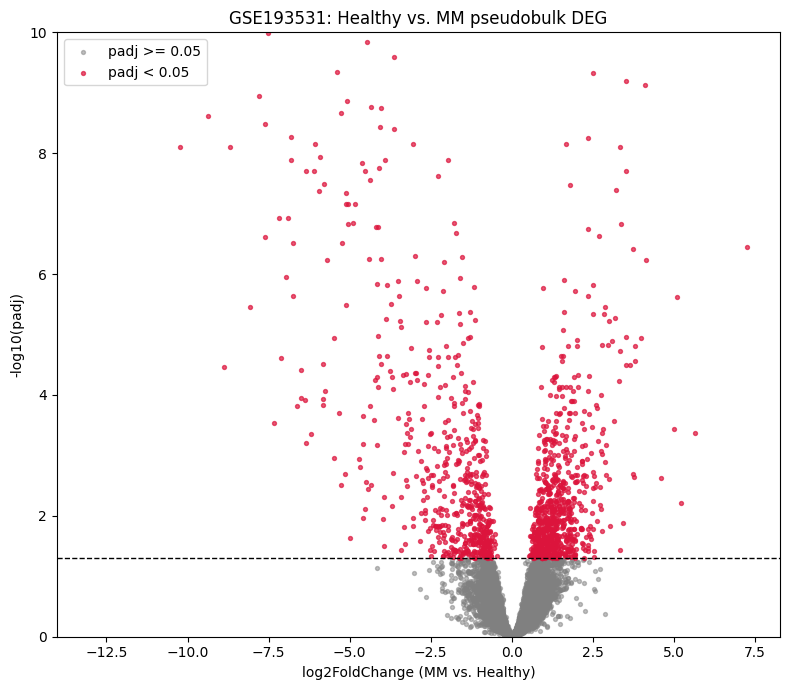

Significant genes (padj < 0.05): 1,428 / 10,345


In [12]:
ALPHA = 0.05

plot_df = deseq2_results.dropna(subset=["padj", "log2FoldChange"]).copy()
plot_df["neg_log10_padj"] = -np.log10(plot_df["padj"].clip(lower=1e-300))
significant = plot_df["padj"] < ALPHA

plt.figure(figsize=(8, 7))
plt.scatter(plot_df.loc[~significant, "log2FoldChange"], plot_df.loc[~significant, "neg_log10_padj"], s=8, color="grey", alpha=0.5, label=f"padj >= {ALPHA}")
plt.scatter(plot_df.loc[significant, "log2FoldChange"], plot_df.loc[significant, "neg_log10_padj"], s=8, color="crimson", alpha=0.7, label=f"padj < {ALPHA}")
plt.axhline(-np.log10(ALPHA), color="black", linestyle="--", linewidth=1)
plt.xlabel("log2FoldChange (MM vs. Healthy)")
plt.ylabel("-log10(padj)")
plt.title("GSE193531: Healthy vs. MM pseudobulk DEG")
plt.legend()
plt.tight_layout()
plt.ylim(bottom=0, top=10)
plt.show()

print(f"Significant genes (padj < {ALPHA}): {int(significant.sum()):,} / {len(plot_df):,}")

In [11]:
results_path = RESULTS_DIR / "pseudobulk_deg" / f"{COHORT}_healthy_vs_mm_deseq2_results.csv"
deseq2_results.to_csv(results_path)
print(f"Saved DESeq2 results -> {results_path}")
display(deseq2_results.head(20))

Saved DESeq2 results -> ../results/GSE193531/pseudobulk_deg/GSE193531_healthy_vs_mm_deseq2_results.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,lfc_source
IGLC3,211906.284978,-10.910657,0.608428,-17.932524,6.572721e-72,6.799480e-68,unshrunken_fallback
IGHA1,200576.358326,-8.492125,0.626392,-13.557205,7.182149e-42,3.714967e-38,unshrunken_fallback
IGLV3-21,2071.445840,-13.014539,1.036694,-12.553881,3.784919e-36,1.305166e-32,unshrunken_fallback
TNFRSF18,72.266018,-7.330952,0.593510,-12.351861,4.759728e-35,1.230985e-31,unshrunken_fallback
IGHV4-39,120.281011,-9.918975,0.842076,-11.779200,4.996530e-32,1.033782e-28,unshrunken_fallback
IGHV4-59,102.802876,-6.980434,0.629163,-11.094802,1.329538e-28,2.292346e-25,unshrunken_fallback
IGLC2,429621.961303,-6.354011,0.576380,-11.023997,2.927627e-28,4.326614e-25,unshrunken_fallback
IGHV1-46,80.318556,-9.786035,0.913030,-10.718194,8.361969e-27,1.081307e-23,unshrunken_fallback
IGLV1-44,621.862623,-12.167175,1.186717,-10.252803,1.149609e-24,1.321412e-21,unshrunken_fallback
IGHV3-48,49.373152,-7.720411,0.753893,-10.240725,1.302567e-24,1.347505e-21,unshrunken_fallback
